In [3]:
import pandas as pd, numpy as np
px  = pd.read_csv("/content/Stocks_data - Stocks_data.csv")
fac = pd.read_csv("/content/market_Factor_risk_Free - market_Factor_risk_Free.csv")
print(px.shape, fac.shape)      # rows, columns
print(px.head()); print(fac.head())
print(px.isna().sum().sort_values().tail(8))   # which stocks have missing prices?

(3652, 52) (3469, 3)
        Dates  EIM IS Equity  AXSB IS Equity  BJFIN IS Equity  \
0  01-01-2009          23.50          103.37            14.78   
1  02-01-2009          24.01          108.38            15.52   
2  05-01-2009          23.99          112.02            16.30   
3  06-01-2009          23.74          113.95            17.11   
4  07-01-2009          22.45          104.42            17.32   

   SBILIFE IS Equity  RELIANCE IS Equity  ITC IS Equity  MM IS Equity  \
0                NaN              283.07          57.22         70.79   
1                NaN              290.23          58.17         72.15   
2                NaN              308.16          57.65         74.06   
3                NaN              309.30          58.13         79.58   
4                NaN              270.91          56.03         75.65   

   SBIN IS Equity  HNDL IS Equity  ...  HDFCLIFE IS Equity  DIVI IS Equity  \
0          131.63           54.20  ...                 NaN          333

In [4]:
px = pd.read_csv("/content/Stocks_data - Stocks_data.csv", na_values=["#N/A N/A", "#N/A"])
px["Dates"] = pd.to_datetime(px["Dates"], format="%d-%m-%Y")
px = px.set_index("Dates").sort_index()

nifty  = px.iloc[:, -1]                      # last column = Nifty 50
stocks = px.iloc[:, :-1]
stocks = stocks.dropna(axis=1)               # drop any stock with missing data
print(stocks.shape)                          # expect 45 stocks

(3652, 45)


In [5]:
fac = pd.read_csv("/content/market_Factor_risk_Free - market_Factor_risk_Free.csv").dropna()
fac["Date"] = pd.to_datetime(fac["Date"], format="%d-%m-%Y")
fac = fac.set_index("Date").sort_index()
fac["MF"] = fac["MF"] / 100      # percent -> decimal
fac["RF"] = fac["RF"] / 100      # values look like percent per day (see note below)

In [6]:
rets = pd.concat([stocks, nifty], axis=1).pct_change().dropna()   # (P_t / P_t-1) - 1
common = rets.index.intersection(fac.index)
rets, fac = rets.loc[common], fac.loc[common]
R = rets.iloc[:, :-1]      # stocks
B = rets.iloc[:, -1]       # Nifty daily returns
print(R.shape)             # about 3454 days x 45 stocks

(3454, 45)


In [7]:
f = R.loc["2009-01-01":"2009-06-30"]
mu    = f.mean().values            # average daily return of each stock
Sigma = np.cov(f.values, rowvar=False)   # 45 x 45 covariance matrix
rf    = fac.loc[f.index, "RF"].mean()
N     = f.shape[1]

In [8]:
from scipy.optimize import minimize
cons = {"type": "eq", "fun": lambda w: w.sum() - 1}
bnds = [(0, None)] * N                       # no short selling
w0   = np.ones(N) / N
gmv  = minimize(lambda w: w @ Sigma @ w * 1e4, w0, method="SLSQP",
                bounds=bnds, constraints=cons, options={"ftol": 1e-14}).x

In [9]:
neg_sharpe = lambda w: -(w @ mu - rf) / np.sqrt(w @ Sigma @ w)
mv = minimize(neg_sharpe, w0, method="SLSQP", bounds=bnds, constraints=cons).x

In [10]:
ew = np.ones(N) / N

In [11]:
from scipy import stats
y = f.values - fac.loc[f.index, "RF"].values[:, None]   # excess returns, T x N
x = fac.loc[f.index, "MF"].values
T = len(x)
beta  = ((x - x.mean())[:, None] * (y - y.mean(0))).sum(0) / ((x - x.mean())**2).sum()
alpha = y.mean(0) - beta * x.mean()
resid = y - alpha - np.outer(x, beta)
s2    = (resid**2).sum(0) / (T - 2)
se_a  = np.sqrt(s2 * (1/T + x.mean()**2 / ((x - x.mean())**2).sum()))
p     = 2 * stats.t.sf(np.abs(alpha / se_a), df=T - 2)
sel   = (alpha > 0) & (p < 0.05)
active = sel / sel.sum() if sel.any() else None   # None = hold the Nifty instead

In [12]:
h  = R.loc["2009-07-01":"2009-09-30"]
asset_growth = (1 + h).prod().values - 1       # each stock's 3-month return
ret_gmv = gmv @ asset_growth                   # sum of w_i * (prod(1+R) - 1)
ret_nifty = (1 + B.loc[h.index]).prod() - 1

In [16]:
from scipy.optimize import minimize
from scipy import stats

def clean(w):                       # remove tiny numerical noise, re-normalise to sum 1
    w = np.where(w < 1e-8, 0, w)
    return w / w.sum()

def make_weights(f):
    """Takes the formation-window returns f and returns GMV, MV, EW, Active weights."""
    N     = f.shape[1]
    mu    = f.mean().values
    Sigma = np.cov(f.values, rowvar=False)
    rf    = fac.loc[f.index, "RF"].mean()
    cons  = {"type": "eq", "fun": lambda w: w.sum() - 1}
    bnds  = [(0, None)] * N
    w0    = np.ones(N) / N

    gmv = minimize(lambda w: w @ Sigma @ w * 1e4, w0, method="SLSQP",
                   bounds=bnds, constraints=cons, options={"ftol": 1e-14}).x
    mv  = minimize(lambda w: -(w @ mu - rf) / np.sqrt(w @ Sigma @ w), w0,
                   method="SLSQP", bounds=bnds, constraints=cons).x
    ew  = w0

    # Active: CAPM regression for every stock
    y = f.values - fac.loc[f.index, "RF"].values[:, None]
    x = fac.loc[f.index, "MF"].values
    T = len(x)
    beta  = ((x - x.mean())[:, None] * (y - y.mean(0))).sum(0) / ((x - x.mean())**2).sum()
    alpha = y.mean(0) - beta * x.mean()
    resid = y - alpha - np.outer(x, beta)
    s2    = (resid**2).sum(0) / (T - 2)
    se_a  = np.sqrt(s2 * (1/T + x.mean()**2 / ((x - x.mean())**2).sum()))
    p     = 2 * stats.t.sf(np.abs(alpha / se_a), df=T - 2)
    sel   = (alpha > 0) & (p < 0.05)
    act   = sel / sel.sum() if sel.any() else None
    return clean(gmv), clean(mv), ew, act

rows, rf_hold = [], []
for k in range(54):
    fs = pd.Timestamp("2009-01-01") + pd.DateOffset(months=3*k)
    fe = fs + pd.DateOffset(months=6)          # formation window: [fs, fe)
    he = fe + pd.DateOffset(months=3)          # holding window:   [fe, he)
    f = R[(R.index >= fs) & (R.index < fe)]
    h = R[(R.index >= fe) & (R.index < he)]

    gmv, mv, ew, act = make_weights(f)

    growth    = (1 + h).prod().values - 1                        # each stock's 3-month return
    ret_nifty = (1 + B.loc[h.index]).prod() - 1
    ret_act   = ret_nifty if act is None else act @ growth       # fallback = Nifty
    rows.append([gmv @ growth, mv @ growth, ew @ growth, ret_act, ret_nifty])
    rf_hold.append((1 + fac.loc[h.index, "RF"]).prod() - 1)

Rmat = pd.DataFrame(rows, columns=["GMV", "MV", "EW", "Active", "NIFTY50"])
print(Rmat.shape)        # must print (54, 5)
Rmat.head()

(54, 5)


,GMV,MV,EW,Active,NIFTY50
0,0.085749,0.150361,0.246693,0.096861,0.184766
1,0.110550,0.195919,0.106484,0.130071,0.023103
2,0.000067,0.011879,0.041375,-0.002977,0.009239
3,0.087544,0.065036,0.065387,-0.064716,0.012078
4,0.127740,0.199794,0.175833,0.281550,0.135049


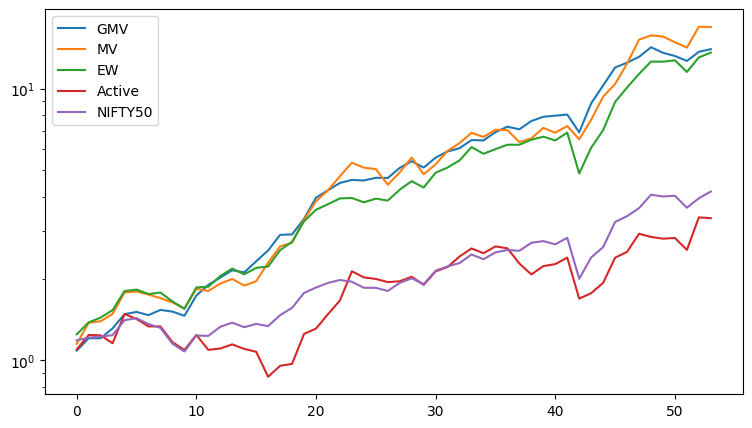

,Ann return %,Ann vol %,Sharpe,IR
GMV,21.58,13.69,0.98,0.87
MV,23.28,18.52,0.79,0.71
EW,21.32,18.93,0.69,1.84
Active,9.34,22.99,0.12,-0.10
NIFTY50,11.18,17.11,0.26,NaN


In [17]:
import matplotlib.pyplot as plt
(1 + Rmat).cumprod().plot(logy=True, figsize=(9,5)); plt.show()

L       = np.log1p(Rmat)
ann_ret = (np.exp(4 * L.mean()) - 1) * 100
ann_vol = 2 * L.std() * 100
LF      = np.log1p(pd.Series(rf_hold))
sharpe  = 4 * L.sub(LF, axis=0).mean() / (2 * L.sub(LF, axis=0).std())
D       = L.sub(L["NIFTY50"], axis=0)
IR      = 4 * D.mean() / (2 * D.std())

pd.DataFrame({"Ann return %": ann_ret, "Ann vol %": ann_vol, "Sharpe": sharpe, "IR": IR}).round(2)

In [18]:
Rmat.index = range(1, 55)      # window numbers 1 to 54
Rmat.index.name = "window"
Rmat.head(10)

,GMV,MV,EW,Active,NIFTY50
window,,,,,
1,0.085749,0.150361,0.246693,0.096861,0.184766
2,0.110550,0.195919,0.106484,0.130071,0.023103
3,0.000067,0.011879,0.041375,-0.002977,0.009239
4,0.087544,0.065036,0.065387,-0.064716,0.012078
5,0.127740,0.199794,0.175833,0.281550,0.135049
6,0.019170,0.008035,0.012097,-0.041555,0.017338
7,-0.026860,-0.026061,-0.037080,-0.061147,-0.049026
8,0.045392,-0.029987,0.013011,0.000253,-0.031943
9,-0.014295,-0.035337,-0.072909,-0.124686,-0.124686


In [19]:
Rmat.to_csv("returns_matrix_nx5.csv", float_format="%.8f")

In [20]:
from google.colab import files
files.download("returns_matrix_nx5.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>